,Model,AVT (%),UVBR (%),NIRBR (%)
0,net_inverse_13layers_1.pth,78.3099,65.4504,53.7048
1,net_inverse_13layers_2.pth,89.0855,79.4010,75.8255
2,net_inverse_13layers_3.pth,82.4859,89.8357,83.4201
3,net_inverse_13layers_4.pth,82.8910,85.3921,73.9117
4,net_inverse_13layers_5.pth,79.8228,80.9855,67.7016


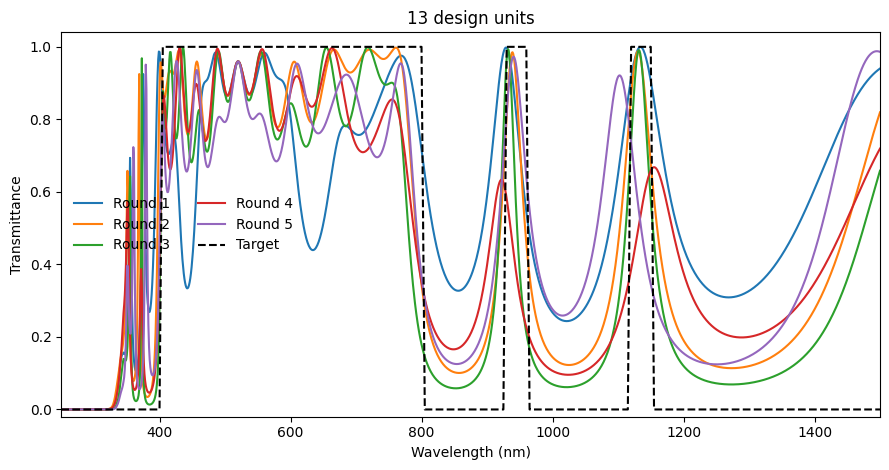

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display

N_UNITS = 13  
TARGET_FILE = "target_spectrum.txt" 
BASE_DIR = Path.cwd()  

torch.set_num_threads(4)
trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz


class InverseNetwork(nn.Module):
    def __init__(self, units):
        super().__init__()
        self.units = units
        layers, width = [], 251
        for hidden in [1024, 2048, 1024, 1024]:
            layers += [nn.Linear(width, hidden), nn.BatchNorm1d(hidden), nn.GELU()]
            width = hidden
        layers.append(nn.Linear(width, units * 4))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).reshape(-1, self.units, 4).argmax(-1)


def transmittance(sequence, thickness):
    matrix = np.broadcast_to(np.eye(2, dtype=complex), (len(w), 2, 2)).copy()
    for material, d in zip(sequence, thickness):
        index = nk[:, material]
        phase = 2 * np.pi * index * d / w
        c, s = np.cos(phase), np.sin(phase)
        layer = np.empty_like(matrix)
        layer[:, 0, 0] = layer[:, 1, 1] = c
        layer[:, 0, 1] = 1j * s / index
        layer[:, 1, 0] = 1j * index * s
        matrix = matrix @ layer
    b = matrix[:, 0, 0] + 1.5 * matrix[:, 0, 1]
    c = matrix[:, 1, 0] + 1.5 * matrix[:, 1, 1]
    return 1.5 * np.abs(2 / (b + c))**2

optical = np.loadtxt(BASE_DIR / "nk.txt", skiprows=1)
solar_data = np.loadtxt(BASE_DIR / "solar_spectrum.txt")
target = np.loadtxt(BASE_DIR / TARGET_FILE)
assert target.shape == (251,)
assert np.isfinite(target).all() and np.all((target >= 0) & (target <= 1))
w_input = np.arange(250., 1501., 5.)
w = np.arange(250., 1501., 1.)
nk = np.column_stack([
    np.interp(w, optical[:, 0], optical[:, 1 + 2*m])
    - 1j * np.interp(w, optical[:, 0], optical[:, 2 + 2*m]) for m in range(4)
])
n_520 = np.array([np.interp(520, optical[:, 0], optical[:, 1 + 2*m]) for m in range(4)])
solar = np.interp(w, solar_data[:, 0], solar_data[:, 1])


def calculate_metrics(T):
    vis = (w >= 400) & (w <= 800)
    avt = trapz(T[vis], w[vis]) / 400
    blocking = []
    for lo, hi in [(280, 400), (800, 1500)]:
        mask = (w >= lo) & (w <= hi)
        blocking.append(trapz((1-T[mask])*solar[mask], w[mask]) / trapz(solar[mask], w[mask]))
    return 100 * np.array([avt, *blocking])

model_dir = BASE_DIR / f"{N_UNITS}layers_inverse_model"
paths = sorted(model_dir.glob(f"net_inverse_{N_UNITS}layers_*.pth"),
               key=lambda p: int(p.stem.rsplit("_", 1)[1]))
if not paths:
    raise FileNotFoundError(f"cannot find{model_dir}")

rows = []
fig, ax = plt.subplots(figsize=(9, 4.8))
x = torch.tensor(target[None, :], dtype=torch.float32)
for path in paths:
    model = InverseNetwork(N_UNITS)
    model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    model.eval()
    with torch.inference_mode():
        sequence = model(x)[0].numpy()
    thickness = 520 / (2 * n_520[sequence])
    T = transmittance(sequence, thickness)
    avt, uvbr, nirbr = calculate_metrics(T)
    rows.append({"Model": path.name, "AVT (%)": avt, "UVBR (%)": uvbr, "NIRBR (%)": nirbr})
    ax.plot(w, T, lw=1.5, label=f"Round {path.stem.rsplit('_', 1)[1]}")

results = pd.DataFrame(rows)
display(results.round(4))
ax.plot(w_input, target, "k--", lw=1.5, label="Target")
ax.set(xlabel="Wavelength (nm)", ylabel="Transmittance",
       xlim=(250, 1500), ylim=(-0.02, 1.04), title=f"{N_UNITS} design units")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
plt.show()
